# Hotel Bookings: Exploratory Data Analysis

Preserve `raw_bookings` and analyze a separate `bookings_copy` with normalized missing markers
and numeric types. Keep all rows and columns: leakage removal, deduplication and all-zero
guest filtering belong to `src/preprocessing.py`. IQR outliers are flagged, not removed.

Use the existing loader in `src/data_loader.py`, the shared copy builder in
`src/preprocessing.py`, and reusable analysis functions in `src/eda.py`.
Only ten selected features have observed-value listings. Plots cover IQR outliers, seasonal and
yearly prices, and monthly/yearly booked guest counts for both hotels.

No data, chart files or analysis tables are exported. Run the notebook from top to bottom.

[Go to the correlation matrix](#correlation-matrix).


## 1. Project Location and Imports

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML
from IPython.display import display


def find_project_root(start: Path) -> Path:
    """Locate this project using its existing loader, independently of notebook cwd."""
    candidates = [start, *start.parents, start / "hotel-cancellation"]
    for candidate in candidates:
        if (candidate / "src" / "data_loader.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the hotel-cancellation project. "
        "Run the notebook from the project root or the notebooks/ directory."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_hotel_bookings
from src.eda import (
    NUMERIC_COLUMNS, OUTLIER_COLUMNS, VALUE_COUNT_COLUMNS,
    feature_value_counts, duplicate_summary, iqr_outliers,
    plot_iqr_checks, seasonal_room_prices, plot_seasonal_prices,
    zero_guest_mask, yearly_room_prices, guest_counts, plot_hotel_trends,
)


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
print(f"Project directory: {PROJECT_ROOT}")

Project directory: C:\Users\lenovo\Documents\CODING\cmpe481_term_project\hotel-cancellation


## 2. Load Data Using the Existing Loader

In [2]:
raw_bookings = load_hotel_bookings()
raw_fingerprint = pd.util.hash_pandas_object(raw_bookings, index=True).copy()

print(f"Row count: {raw_bookings.shape[0]:,}")
print(f"Column count: {raw_bookings.shape[1]}")
display(raw_bookings.head())

Row count: 119,390
Column count: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NULL,NULL,0,Transient,0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NULL,NULL,0,Transient,0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NULL,NULL,0,Transient,75,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,NULL,0,Transient,75,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,NULL,0,Transient,98,0,1,Check-Out,2015-07-03


## 3. `info()` — Raw Data Structure

The loader reads every column as `string` and uses `keep_default_na=False`.
Consequently, `Non-Null Count` treats literal strings such as `NULL` and `NA` as populated values.
This output alone does not establish the semantic types of the columns.

In [3]:
raw_bookings.info(show_counts=True, memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype 
---  ------                          --------------   ----- 
 0   hotel                           119390 non-null  string
 1   is_canceled                     119390 non-null  string
 2   lead_time                       119390 non-null  string
 3   arrival_date_year               119390 non-null  string
 4   arrival_date_month              119390 non-null  string
 5   arrival_date_week_number        119390 non-null  string
 6   arrival_date_day_of_month       119390 non-null  string
 7   stays_in_weekend_nights         119390 non-null  string
 8   stays_in_week_nights            119390 non-null  string
 9   adults                          119390 non-null  string
 10  children                        119390 non-null  string
 11  babies                          119390 non-null  string
 12  meal                          

## 4. `describe()` — Raw Value Summary

Because the raw columns are strings, this output shows `count`, `unique`, `top`, and `freq`.
Numeric means and quantiles are calculated below using a separate analysis copy.

In [4]:
display(raw_bookings.describe(include="all").T)

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
is_canceled,119390,2,0,75166
lead_time,119390,479,0,6345
arrival_date_year,119390,3,2016,56707
arrival_date_month,119390,12,August,13877
arrival_date_week_number,119390,53,33,3580
arrival_date_day_of_month,119390,31,17,4406
stays_in_weekend_nights,119390,17,0,51998
stays_in_week_nights,119390,35,2,33684
adults,119390,14,2,89680


## 5. Null and Missing-Value Checks

First inspect pandas null counts, then audit textual missing-value markers in the file.
`NULL`, `NA`, `N/A`, `NaN`, `nan`, `null`, empty strings, and whitespace-only cells are treated as missing candidates.
Update the single configuration below if the dataset's missing-value policy changes.
`None` and `Unknown` are not automatically treated as missing.

`pandas_null_count`, `blank_count`, and `missing_token_count` are mutually exclusive counts.
Percentages use all rows as the denominator. Raw values remain unchanged.

In [5]:
MISSING_TOKENS = frozenset({"NULL", "null", "NA", "N/A", "NaN", "nan"})


def missing_value_summary(
    frame: pd.DataFrame,
    missing_tokens: frozenset[str],
) -> pd.DataFrame:
    """Report actual nulls, blanks and configured textual markers without mutation."""
    rows = []
    for column in frame.columns:
        values = frame[column].astype("string")
        stripped = values.str.strip()
        nulls = values.isna()
        blanks = stripped.eq("").fillna(False) & ~nulls
        tokens = stripped.isin(missing_tokens) & ~nulls & ~blanks
        total = int((nulls | blanks | tokens).sum())
        rows.append({
            "column": column,
            "pandas_null_count": int(nulls.sum()),
            "blank_count": int(blanks.sum()),
            "missing_token_count": int(tokens.sum()),
            "total_missing_count": total,
            "missing_percent": 100 * total / len(frame) if len(frame) else 0.0,
        })
    return pd.DataFrame(rows).set_index("column").sort_values(
        "total_missing_count", ascending=False
    )


print("Direct pandas isna() check:")
display(raw_bookings.isna().sum().rename("pandas_null_count").to_frame())

missing_summary = missing_value_summary(raw_bookings, MISSING_TOKENS)
print("Missing-value check including textual markers:")
display(missing_summary)
print(f"Total candidate missing cells: {missing_summary['total_missing_count'].sum():,}")

Direct pandas isna() check:


,pandas_null_count
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


Missing-value check including textual markers:


,pandas_null_count,blank_count,missing_token_count,total_missing_count,missing_percent
column,,,,,
company,0,0,112593,112593,94.306893
agent,0,0,16340,16340,13.686238
country,0,0,488,488,0.408744
children,0,0,4,4,0.003350
arrival_date_month,0,0,0,0,0.000000
arrival_date_week_number,0,0,0,0,0.000000
hotel,0,0,0,0,0.000000
is_canceled,0,0,0,0,0.000000
stays_in_weekend_nights,0,0,0,0,0.000000


Total candidate missing cells: 129,425


## 6. Create `bookings_copy`

Normalize missing markers and convert explicitly configured numeric fields on a separate copy.
Unexpected numeric text raises an error. `agent` and `company` remain string codes.
Keep all rows and columns, including `reservation_status` and `reservation_status_date`.
Leakage columns are removed only in `src/preprocessing.py`.
Binary labels and calendar codes are not continuous measurements.


In [6]:
def build_bookings_copy(
    frame: pd.DataFrame,
    numeric_columns: tuple[str, ...],
    missing_tokens: frozenset[str],
) -> pd.DataFrame:
    """Normalize missing markers and convert numeric columns on an independent copy."""
    absent = sorted(set(numeric_columns) - set(frame.columns))
    if absent:
        raise ValueError(f"Expected numeric columns not found: {absent}")
    view = frame.copy(deep=True)
    for column in view.columns:
        stripped = view[column].astype("string").str.strip()
        missing = stripped.isin(missing_tokens) | stripped.eq("").fillna(False)
        view[column] = view[column].mask(missing, pd.NA)
    for column in numeric_columns:
        view[column] = pd.to_numeric(view[column], errors="raise")
    return view


bookings_copy = build_bookings_copy(
    raw_bookings, NUMERIC_COLUMNS, MISSING_TOKENS
)
bookings_copy.info(show_counts=True)

# Each candidate missing cell must appear in the analysis copy as a pandas null.
assert bookings_copy.isna().sum().eq(missing_summary.loc[bookings_copy.columns, "total_missing_count"]).all()
assert bookings_copy.shape == raw_bookings.shape
assert bookings_copy.columns.equals(raw_bookings.columns)
print(f"Analysis copy: {bookings_copy.shape[0]:,} rows, {bookings_copy.shape[1]} columns")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  string 
 1   is_canceled                     119390 non-null  Int64  
 2   lead_time                       119390 non-null  Int64  
 3   arrival_date_year               119390 non-null  Int64  
 4   arrival_date_month              119390 non-null  string 
 5   arrival_date_week_number        119390 non-null  Int64  
 6   arrival_date_day_of_month       119390 non-null  Int64  
 7   stays_in_weekend_nights         119390 non-null  Int64  
 8   stays_in_week_nights            119390 non-null  Int64  
 9   adults                          119390 non-null  Int64  
 10  children                        119386 non-null  Int64  
 11  babies                          119390 non-null  Int64  
 12  meal            

### 6.1. Check Duplicate and All-Zero Guest Rows

Compare duplicate counts in raw data and the normalized analysis copy, using all columns.
Count rows where adults, children and babies are all explicitly zero; missing counts are not zero.
These checks do not remove any rows. Cleaning is performed only in `src/preprocessing.py`.


In [7]:
duplicates = pd.DataFrame({
    "raw_bookings": duplicate_summary(raw_bookings),
    "bookings_copy": duplicate_summary(bookings_copy),
}).T
display(duplicates)

zero_guests = zero_guest_mask(bookings_copy)
print(f"All-zero guest rows: {int(zero_guests.sum()):,}")
print(f"Rows retained for EDA: {len(bookings_copy):,}")


,rows,additional_duplicate_rows,rows_in_duplicate_groups,duplicate_groups,additional_duplicate_percent
raw_bookings,119390.0,31994.0,40165.0,8171.0,26.797889
bookings_copy,119390.0,31994.0,40165.0,8171.0,26.797889


All-zero guest rows: 180
Rows retained for EDA: 119,390


### 6.2. Negative Values in Selected Features

Check the listed numeric features for values below zero. For each matching row, show the number of negative values and the feature values. The percentage uses all rows in `bookings_copy` as its denominator. Missing values are not counted as negative.


In [8]:
NONNEGATIVE_FEATURES = (
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
    "babies", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "days_in_waiting_list",
    "required_car_parking_spaces", "total_of_special_requests", "adr",
)
negative_values = bookings_copy.loc[:, list(NONNEGATIVE_FEATURES)].lt(0)
negative_count_per_row = negative_values.sum(axis=1)
rows_with_negative = negative_count_per_row.gt(0)
negative_row_count = int(rows_with_negative.sum())
negative_row_percentage = 100 * negative_row_count / len(bookings_copy) if len(bookings_copy) else 0.0

print(f"Rows with at least one negative value: {negative_row_count:,} / {len(bookings_copy):,} ({negative_row_percentage:.4f}%)")
negative_rows = bookings_copy.loc[rows_with_negative, list(NONNEGATIVE_FEATURES)].copy()
negative_rows.insert(0, "negative_value_count", negative_count_per_row.loc[rows_with_negative])
display(negative_rows)


Rows with at least one negative value: 1 / 119,390 (0.0008%)


,negative_value_count,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,adr
14969,1,4,6,2,0,0,1,0,2,0,0,0,-6.38


## 7. Numeric `describe()`

`count` is the number of nonmissing observations. `std` is the sample standard deviation (ddof=1).
Inspect the 25th, 50th (median), and 75th percentiles alongside the minimum and maximum.
An extreme value alone is not sufficient justification for removing a record.

In [9]:
numeric_summary = bookings_copy.loc[:, list(NUMERIC_COLUMNS)].describe().T
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0
children,119386.0,0.10389,0.398561,0.0,0.0,0.0,0.0,10.0
babies,119390.0,0.007949,0.097436,0.0,0.0,0.0,0.0,10.0


## 8. Categorical and Text `describe()`

`top` is the most frequent value and `freq` is its count. Missing values are excluded from `count`.
Code fields such as `agent` and `company` remain strings.

In [10]:
categorical_summary = bookings_copy.select_dtypes(
    include=["string", "object", "category", "bool"]
).describe().T
display(categorical_summary)

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
agent,103050,333,9,31961


## 9. Observed Values for Selected Features

List values, counts and percentages for exactly these features:
`hotel`, `is_canceled`, `arrival_date_year`, `meal`, `market_segment`, `distribution_channel`,
`reserved_room_type`, `assigned_room_type`, `deposit_type`, `customer_type`.

Counts use the analysis `bookings_copy`. Missing entries are included when present.
Expand each feature below to inspect all of its observed values.

In [11]:
value_counts = feature_value_counts(bookings_copy, VALUE_COUNT_COLUMNS)
for feature in VALUE_COUNT_COLUMNS:
    counts = value_counts.loc[value_counts["feature"].eq(feature)].drop(columns="feature")
    content = counts.to_html(index=False, escape=True, float_format=lambda value: f"{value:.3f}")
    display(HTML(
        f"<details><summary><strong>{feature}</strong>: {len(counts):,} observed values</summary>"
        f"<div style='max-height:360px;overflow:auto'>{content}</div></details>"
    ))

value,is_missing,count,percent
City Hotel,False,79330,66.446
Resort Hotel,False,40060,33.554


value,is_missing,count,percent
0,False,75166,62.958
1,False,44224,37.042


value,is_missing,count,percent
2016,False,56707,47.497
2017,False,40687,34.079
2015,False,21996,18.424


value,is_missing,count,percent
BB,False,92310,77.318
HB,False,14463,12.114
SC,False,10650,8.920
Undefined,False,1169,0.979
FB,False,798,0.668


value,is_missing,count,percent
Online TA,False,56477,47.305
Offline TA/TO,False,24219,20.286
Groups,False,19811,16.594
Direct,False,12606,10.559
Corporate,False,5295,4.435
Complementary,False,743,0.622
Aviation,False,237,0.199
Undefined,False,2,0.002


value,is_missing,count,percent
TA/TO,False,97870,81.975
Direct,False,14645,12.267
Corporate,False,6677,5.593
GDS,False,193,0.162
Undefined,False,5,0.004


value,is_missing,count,percent
A,False,85994,72.028
D,False,19201,16.083
E,False,6535,5.474
F,False,2897,2.427
G,False,2094,1.754
B,False,1118,0.936
C,False,932,0.781
H,False,601,0.503
P,False,12,0.010
L,False,6,0.005


value,is_missing,count,percent
A,False,74053,62.026
D,False,25322,21.209
E,False,7806,6.538
F,False,3751,3.142
G,False,2553,2.138
C,False,2375,1.989
B,False,2163,1.812
H,False,712,0.596
I,False,363,0.304
K,False,279,0.234


value,is_missing,count,percent
No Deposit,False,104641,87.646
Non Refund,False,14587,12.218
Refundable,False,162,0.136


value,is_missing,count,percent
Transient,False,89613,75.059
Transient-Party,False,25124,21.044
Contract,False,4076,3.414
Group,False,577,0.483


## 11. IQR Bounds and Outlier Listings

- `IQR = Q3 - Q1`
- `upper_bound = Q3 + 1.5 * IQR`
- `lower_bound = Q1 - 1.5 * IQR`

Flag values strictly below the lower bound or strictly above the upper bound. Calculate bounds
on the analysis copy without deduplication or zero-guest removal. Exclude missing observations, identifiers, binary
labels and calendar codes. Zero IQR can flag valid uncommon counts; no IQR outliers are removed.

The full listings remain in memory as `outlier_observations` and `outlier_bookings`.
Preview the first 20 observations per feature below. A booking may be flagged for several
features; observation counts and unique booking counts differ. Original row indices are retained.

In [12]:
IQR_MULTIPLIER = 1.5
iqr_summary, outlier_observations = iqr_outliers(
    bookings_copy, OUTLIER_COLUMNS, multiplier=IQR_MULTIPLIER
)
outlier_bookings = bookings_copy.loc[outlier_observations["source_row_index"].unique()].copy()
display(iqr_summary)
print(f"Flagged feature observations: {len(outlier_observations):,}")
print(f"Unique bookings flagged: {len(outlier_bookings):,}")
for feature in OUTLIER_COLUMNS:
    observations = outlier_observations.loc[outlier_observations["feature"].eq(feature)]
    print(f"{feature}: {len(observations):,} outliers. Preview: first 20 observations.")
    display(observations.head(20))

,nonmissing_count,q1,q3,iqr,lower_bound,upper_bound,below_lower_count,above_upper_count,outlier_count,outlier_percent,zero_iqr
feature,,,,,,,,,,,
lead_time,119390,18.00,160.0,142.00,-195.000,373.000,0,3005,3005,2.516961,False
stays_in_weekend_nights,119390,0.00,2.0,2.00,-3.000,5.000,0,265,265,0.221962,False
stays_in_week_nights,119390,1.00,3.0,2.00,-2.000,6.000,0,3354,3354,2.809281,False
adults,119390,2.00,2.0,0.00,2.000,2.000,23430,6280,29710,24.884831,True
children,119386,0.00,0.0,0.00,0.000,0.000,0,8590,8590,7.195149,True
babies,119390,0.00,0.0,0.00,0.000,0.000,0,917,917,0.768071,True
previous_cancellations,119390,0.00,0.0,0.00,0.000,0.000,0,6484,6484,5.430941,True
previous_bookings_not_canceled,119390,0.00,0.0,0.00,0.000,0.000,0,3620,3620,3.032080,True
booking_changes,119390,0.00,0.0,0.00,0.000,0.000,0,18076,18076,15.140297,True


Flagged feature observations: 91,805
Unique bookings flagged: 64,004
lead_time: 3,005 outliers. Preview: first 20 observations.


,source_row_index,feature,value,lower_bound,upper_bound,direction
0,1,lead_time,737.0,-195.0,373.0,above_upper
1,225,lead_time,394.0,-195.0,373.0,above_upper
2,890,lead_time,460.0,-195.0,373.0,above_upper
3,1516,lead_time,381.0,-195.0,373.0,above_upper
4,1672,lead_time,382.0,-195.0,373.0,above_upper
5,4182,lead_time,709.0,-195.0,373.0,above_upper
6,5704,lead_time,468.0,-195.0,373.0,above_upper
7,5705,lead_time,468.0,-195.0,373.0,above_upper
8,5707,lead_time,468.0,-195.0,373.0,above_upper
9,5708,lead_time,468.0,-195.0,373.0,above_upper


stays_in_weekend_nights: 265 outliers. Preview: first 20 observations.


,source_row_index,feature,value,lower_bound,upper_bound,direction
3005,87,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper
3006,1149,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper
3007,1655,stays_in_weekend_nights,13.0,-3.0,5.0,above_upper
3008,1754,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper
3009,1790,stays_in_weekend_nights,8.0,-3.0,5.0,above_upper
3010,2384,stays_in_weekend_nights,6.0,-3.0,5.0,above_upper
3011,2697,stays_in_weekend_nights,7.0,-3.0,5.0,above_upper
3012,2698,stays_in_weekend_nights,7.0,-3.0,5.0,above_upper
3013,2699,stays_in_weekend_nights,7.0,-3.0,5.0,above_upper
3014,2700,stays_in_weekend_nights,7.0,-3.0,5.0,above_upper


stays_in_week_nights: 3,354 outliers. Preview: first 20 observations.


... (17 outputs left out)

required_car_parking_spaces: 7,416 outliers. Preview: first 20 observations.


,source_row_index,feature,value,lower_bound,upper_bound,direction
81512,25,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81513,29,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81514,53,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81515,54,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81516,55,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81517,61,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81518,65,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81519,75,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81520,78,required_car_parking_spaces,1.0,0.0,0.0,above_upper
81521,89,required_car_parking_spaces,1.0,0.0,0.0,above_upper


total_of_special_requests: 2,877 outliers. Preview: first 20 observations.


,source_row_index,feature,value,lower_bound,upper_bound,direction
88928,12,total_of_special_requests,3.0,-1.5,2.5,above_upper
88929,15,total_of_special_requests,3.0,-1.5,2.5,above_upper
88930,198,total_of_special_requests,3.0,-1.5,2.5,above_upper
88931,200,total_of_special_requests,3.0,-1.5,2.5,above_upper
88932,228,total_of_special_requests,3.0,-1.5,2.5,above_upper
88933,230,total_of_special_requests,3.0,-1.5,2.5,above_upper
88934,264,total_of_special_requests,3.0,-1.5,2.5,above_upper
88935,271,total_of_special_requests,3.0,-1.5,2.5,above_upper
88936,278,total_of_special_requests,3.0,-1.5,2.5,above_upper
88937,337,total_of_special_requests,3.0,-1.5,2.5,above_upper


## 12. Box Plots and Scatter Plots

Each numeric feature has a separate panel. Box plots use 1.5-IQR whiskers. Scatter plots use
original row indices, mark outliers in red, and show both bounds as dashed lines. The row index
is record position, not time. All nonmissing values are included; plots are displayed only.

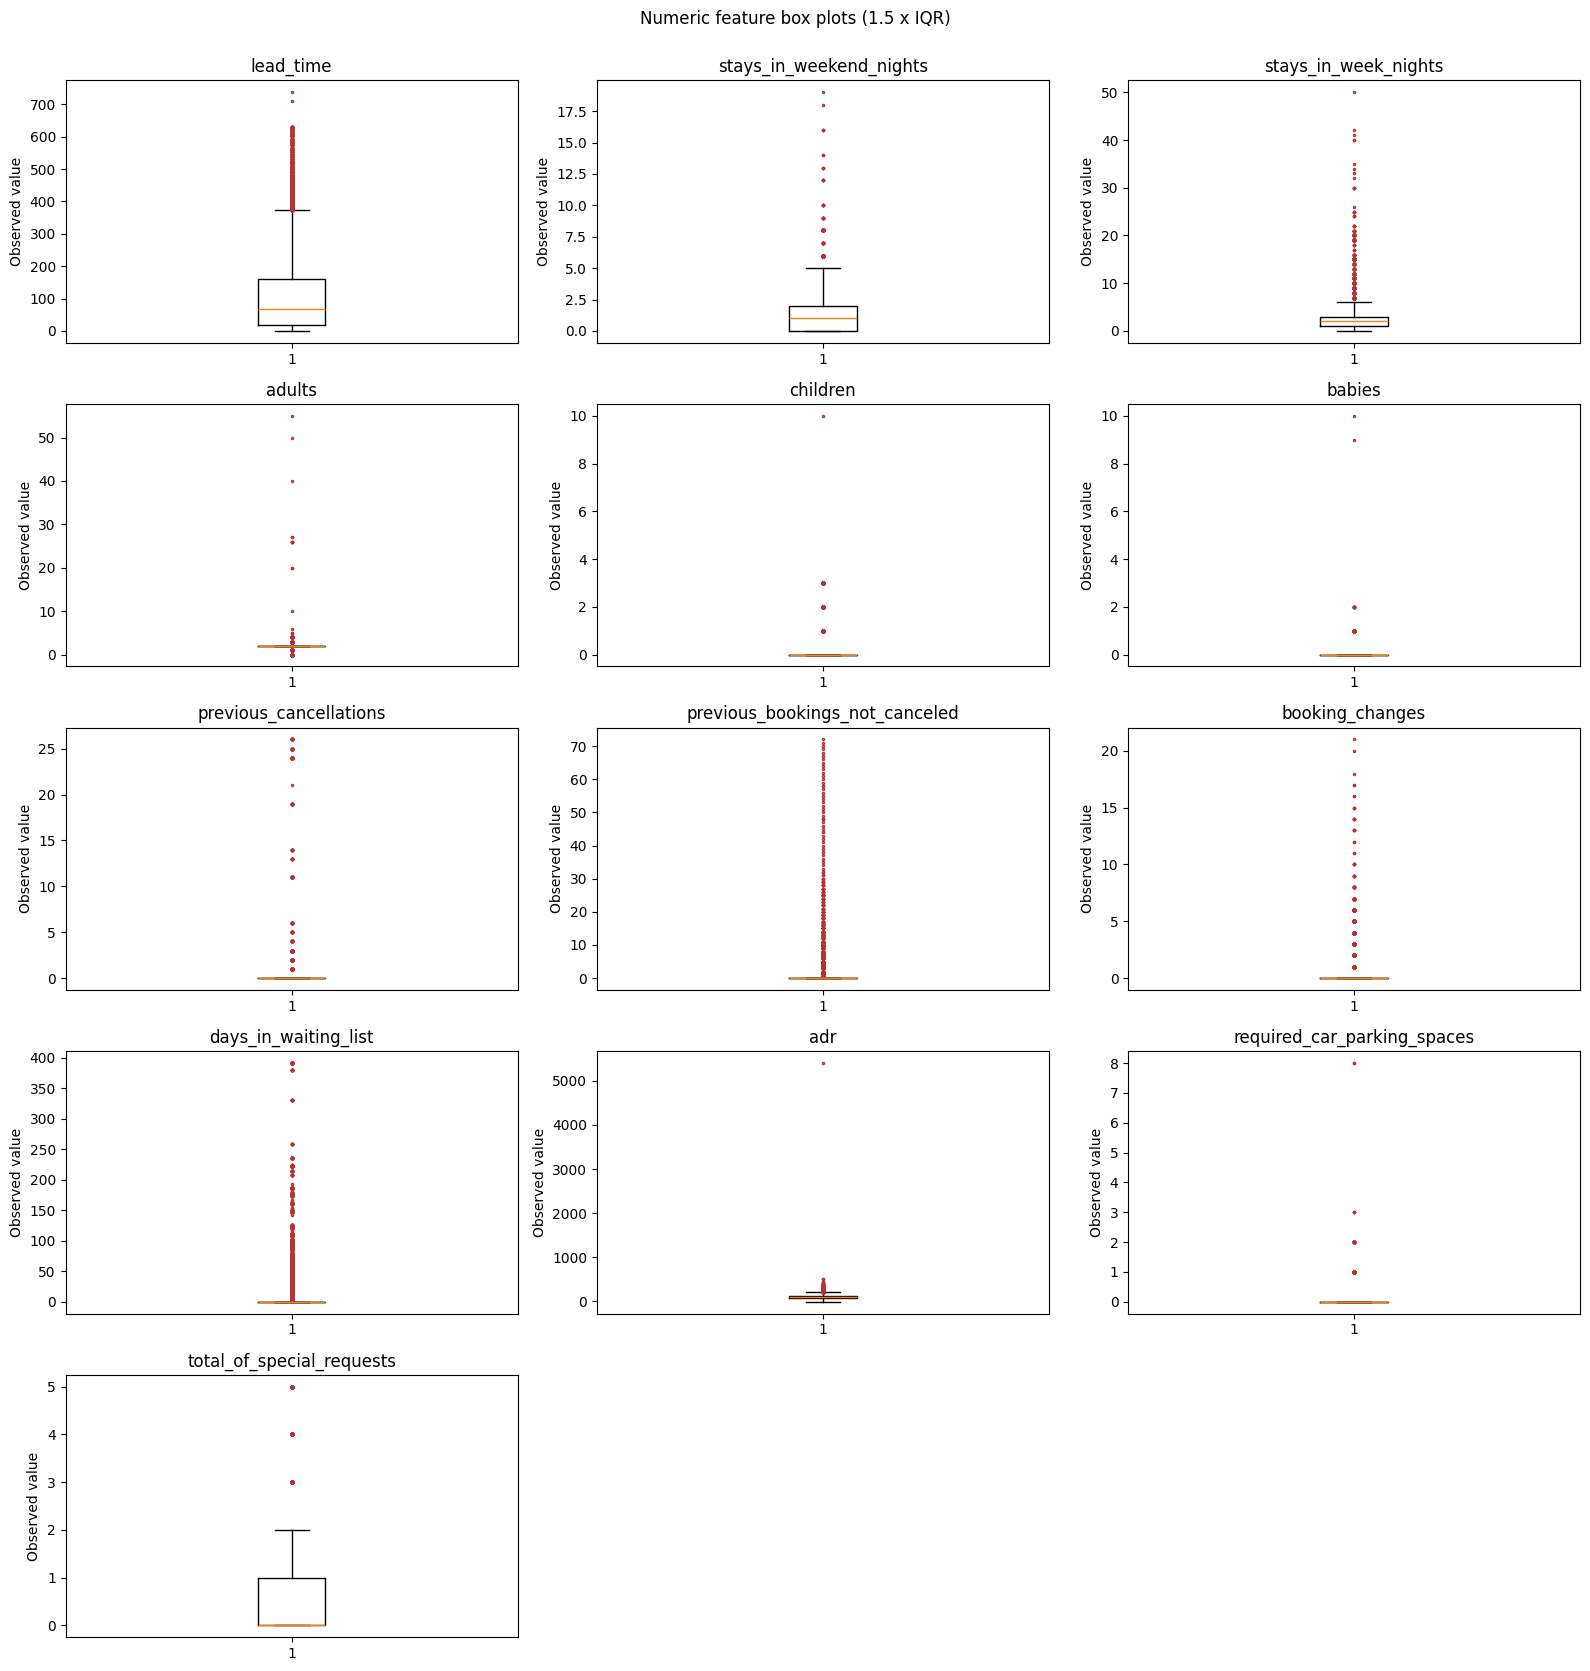

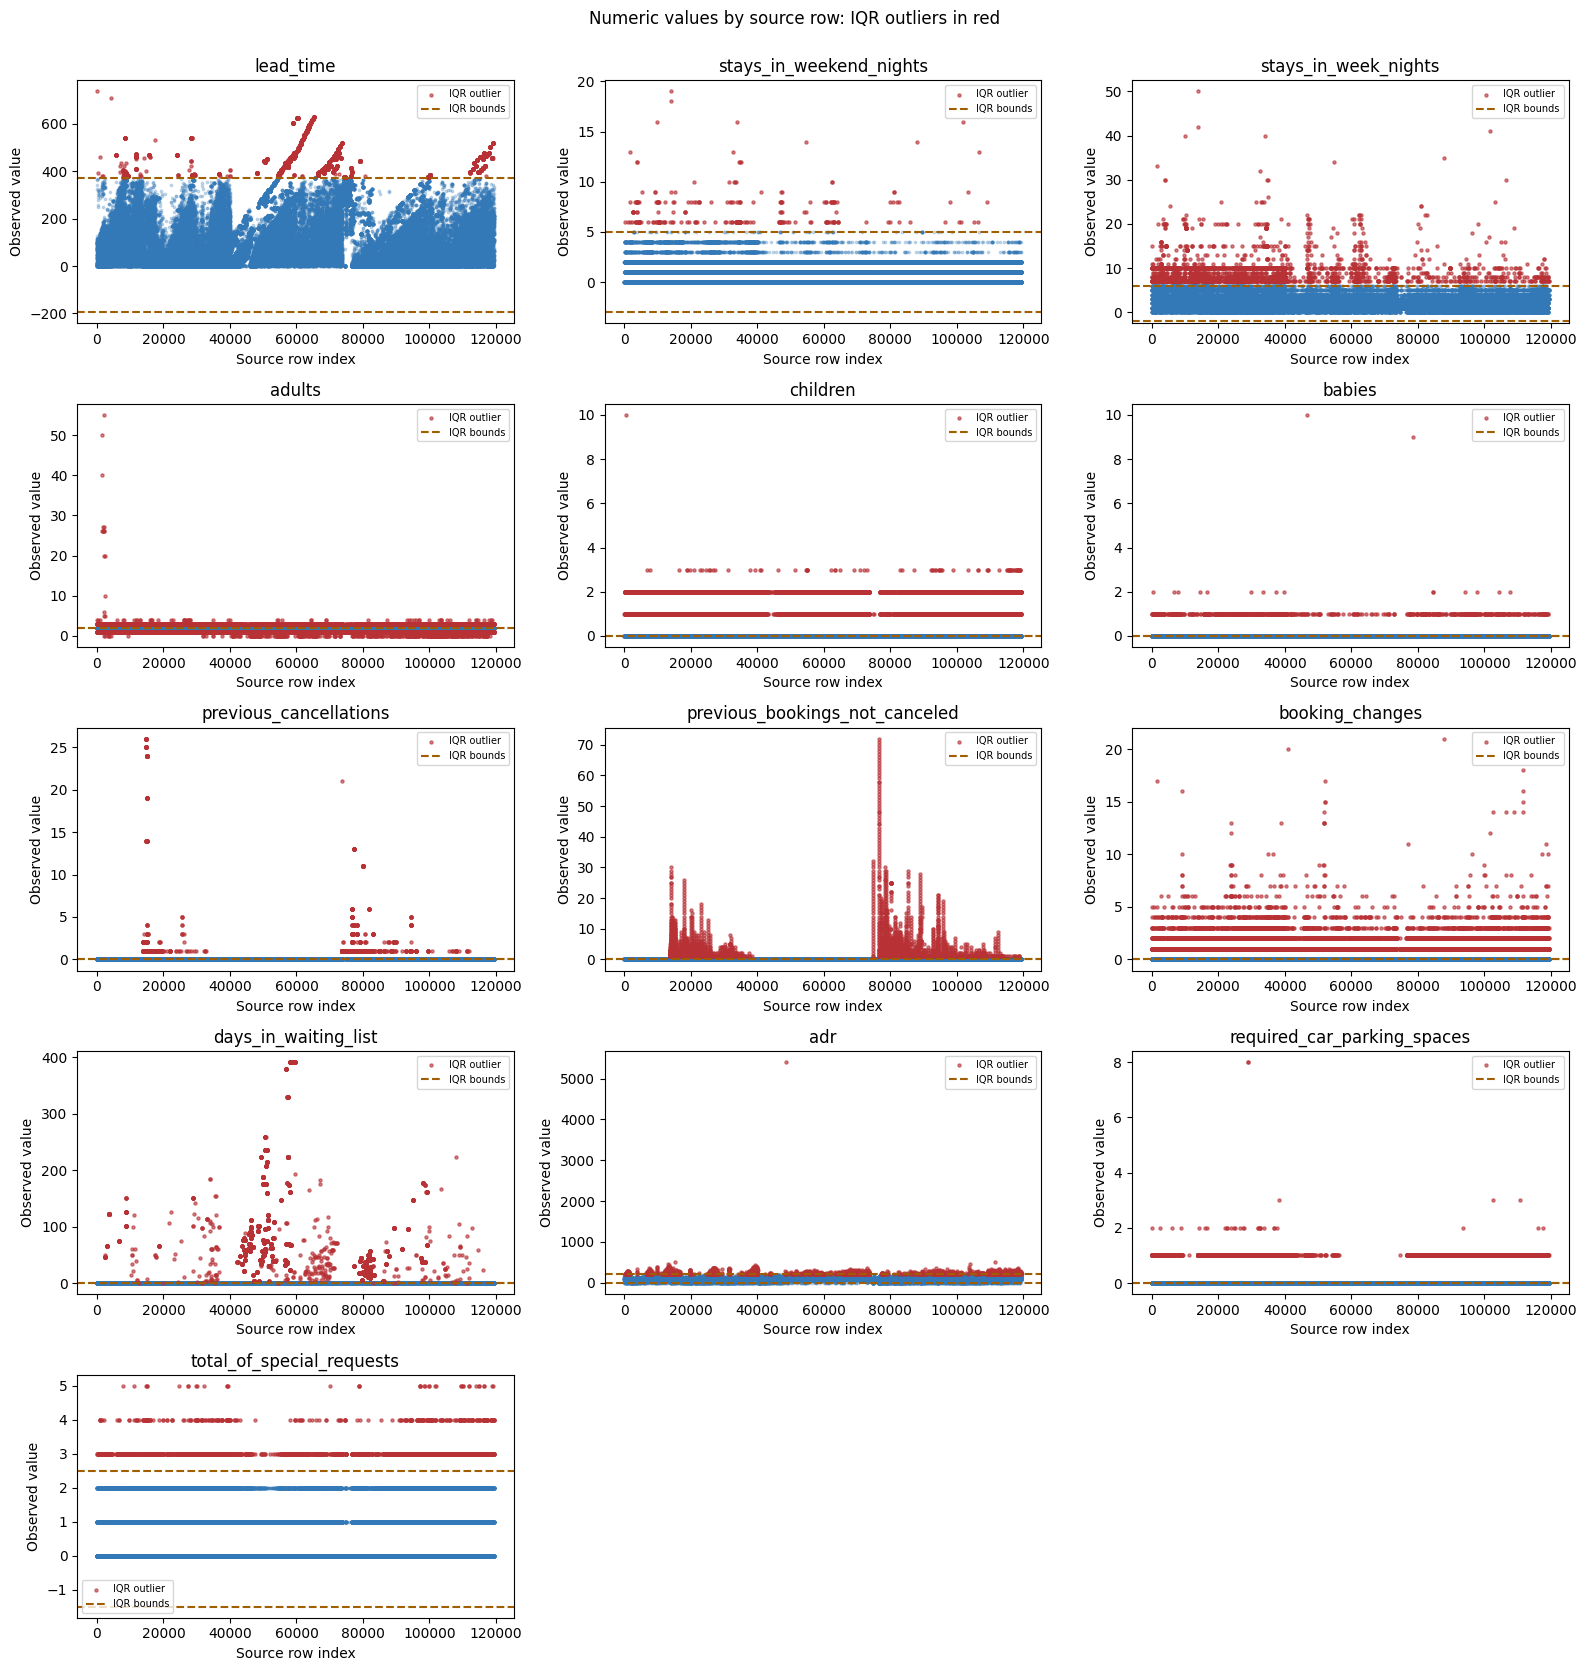

In [13]:
box_figure, scatter_figure = plot_iqr_checks(
    bookings_copy, iqr_summary, multiplier=IQR_MULTIPLIER
)
display(box_figure)
plt.close(box_figure)
display(scatter_figure)
plt.close(scatter_figure)

## 13. Seasonal Price for a Selected Room Type

Change `SELECTED_ROOM_TYPE` to select another reserved room type (default: A).
Compare mean ADR by calendar season, pooling all years, with one line per hotel.
Winter = Dec-Feb, Spring = Mar-May, Summer = Jun-Aug, Autumn = Sep-Nov.
The analysis copy includes canceled bookings and IQR outliers. Mean ADR is booking-weighted,
not room-night-weighted. Missing groups remain gaps. Inspect counts and medians alongside means.

,season,hotel,mean_adr,median_adr,booking_count,priced_booking_count
0,Winter,City Hotel,79.108985,79.0,10272,10272
1,Winter,Resort Hotel,50.528366,45.745,5372,5372
2,Spring,City Hotel,100.175442,97.2,16984,16984
3,Spring,Resort Hotel,60.020533,58.0,6168,6168
4,Summer,City Hotel,102.677117,102.9,19019,19019
5,Summer,Resort Hotel,134.350939,130.0,5993,5993
6,Autumn,City Hotel,95.460536,93.45,16320,16320
7,Autumn,Resort Hotel,57.353964,50.89,5866,5866


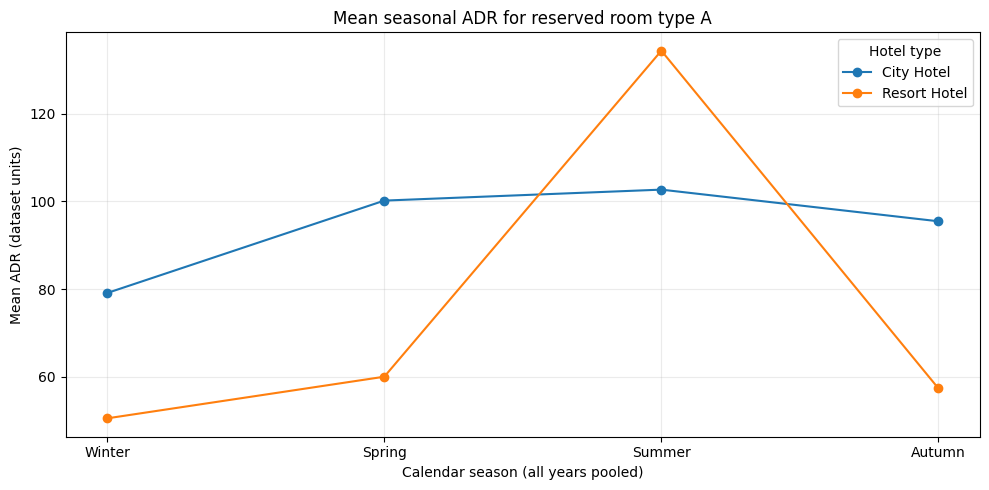

,season,hotel,mean_adr,median_adr,booking_count,priced_booking_count
0,Winter,City Hotel,78.480888,77.875,304,304
1,Winter,Resort Hotel,<NA>,<NA>,<NA>,<NA>
2,Spring,City Hotel,95.756266,94.7,233,233
3,Spring,Resort Hotel,90.0,90.0,2,2
4,Summer,City Hotel,93.718868,92.765,380,380
5,Summer,Resort Hotel,134.0,134.0,1,1
6,Autumn,City Hotel,95.587929,91.6,198,198
7,Autumn,Resort Hotel,<NA>,<NA>,<NA>,<NA>


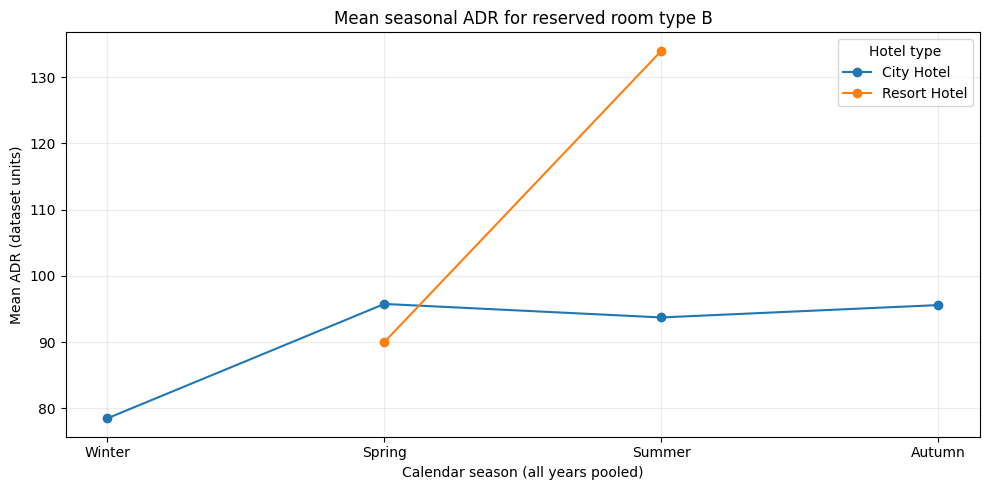

In [14]:
SELECTED_ROOM_TYPE = "A"
seasonal_prices = seasonal_room_prices(bookings_copy, SELECTED_ROOM_TYPE)
display(seasonal_prices)
seasonal_figure = plot_seasonal_prices(seasonal_prices, SELECTED_ROOM_TYPE)
display(seasonal_figure)
plt.close(seasonal_figure)

SELECTED_ROOM_TYPE = "B"
seasonal_prices = seasonal_room_prices(bookings_copy, SELECTED_ROOM_TYPE)
display(seasonal_prices)
seasonal_figure = plot_seasonal_prices(seasonal_prices, SELECTED_ROOM_TYPE)
display(seasonal_figure)
plt.close(seasonal_figure)

## 14. Average Room Price by Year and Hotel

Compare average ADR across all reserved room types for each arrival year, with one line per hotel.
Canceled bookings and IQR outliers are included. Changes can reflect room-type mix as well as
price changes. Means are booking-weighted, not room-night-weighted. ADR units are not inferred.

,arrival_date_year,hotel,mean_adr,median_adr,booking_count,priced_booking_count
0,2015,City Hotel,85.856915,80.0,13682,13682
1,2015,Resort Hotel,89.353417,75.0,8314,8314
2,2016,City Hotel,103.483683,99.0,38140,38140
3,2016,Resort Hotel,87.730762,70.0,18567,18567
4,2017,City Hotel,117.501864,110.0,27508,27508
5,2017,Resort Hotel,108.660217,86.2,13179,13179


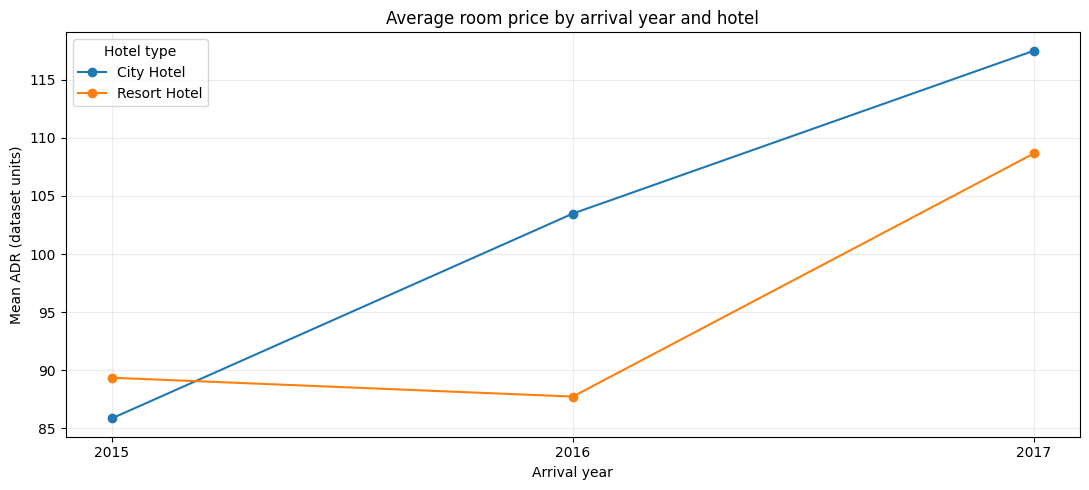

In [15]:
yearly_prices = yearly_room_prices(bookings_copy)
display(yearly_prices)
yearly_price_figure = plot_hotel_trends(
    yearly_prices, "arrival_date_year", "mean_adr",
    "Average room price by arrival year and hotel", "Mean ADR (dataset units)",
)
display(yearly_price_figure)
plt.close(yearly_price_figure)

## 15. Guest Counts by Month and Hotel

Guest count = adults + children + babies, summed over bookings, not distinct visitors or guest nights.
By default, include canceled bookings: these are booked guests, not confirmed arrivals.
Set `INCLUDE_CANCELED_GUESTS = False` to restrict both guest plots to non-canceled bookings.
If any guest count is missing, the row total is unknown and excluded from guest sums.
`complete_guest_count_bookings` reports the number of contributing bookings.

Months are ordered January-December and pooled across all available years. Partial years mean
unequal month coverage; inspect the coverage table. Each hotel has its own line.

,arrival_date_year,arrival_date_month,booking_count
0,2015,August,3889
1,2015,December,2920
2,2015,July,2776
3,2015,November,2340
4,2015,October,4957
5,2015,September,5114
6,2016,April,5428
7,2016,August,5063
8,2016,December,3860
9,2016,February,3891


,arrival_date_month,hotel,guest_count,booking_count,complete_guest_count_bookings
0,January,City Hotel,6721,3736,3736
1,January,Resort Hotel,3803,2193,2193
2,February,City Hotel,9376,4965,4965
3,February,Resort Hotel,5923,3103,3103
4,March,City Hotel,12333,6458,6458
5,March,Resort Hotel,6099,3336,3336
6,April,City Hotel,15101,7480,7480
7,April,Resort Hotel,6899,3609,3609
8,May,City Hotel,15464,8232,8232
9,May,Resort Hotel,6992,3559,3559


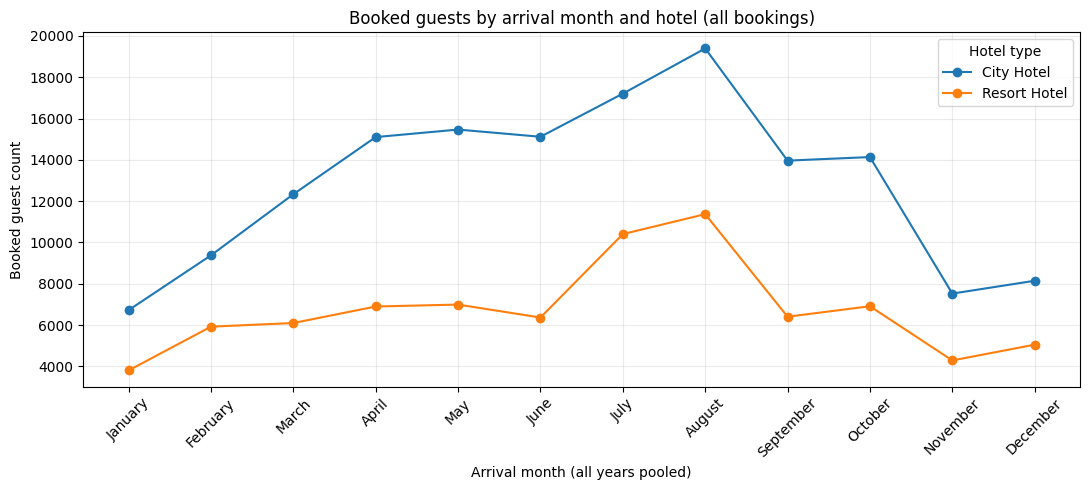

In [16]:
INCLUDE_CANCELED_GUESTS = True
coverage = bookings_copy.groupby(
    ["arrival_date_year", "arrival_date_month"]
).size().rename("booking_count").reset_index()
display(coverage)
monthly_guests = guest_counts(
    bookings_copy, "arrival_date_month", include_canceled=INCLUDE_CANCELED_GUESTS
)
display(monthly_guests)
guest_scope = "all bookings" if INCLUDE_CANCELED_GUESTS else "non-canceled bookings"
monthly_guest_figure = plot_hotel_trends(
    monthly_guests, "arrival_date_month", "guest_count",
    f"Booked guests by arrival month and hotel ({guest_scope})", "Booked guest count",
)
display(monthly_guest_figure)
plt.close(monthly_guest_figure)

## 16. Guest Counts by Year and Hotel

Use the same guest definition and cancellation setting as the monthly chart.
Each hotel has its own line. Partial years must not be compared as full calendar years.

,arrival_date_year,hotel,guest_count,booking_count,complete_guest_count_bookings
0,2015,City Hotel,24972,13682,13678
1,2015,Resort Hotel,16861,8314,8314
2,2016,City Hotel,74577,38140,38140
3,2016,Resort Hotel,36758,18567,18567
4,2017,City Hotel,54920,27508,27508
5,2017,Resort Hotel,26891,13179,13179


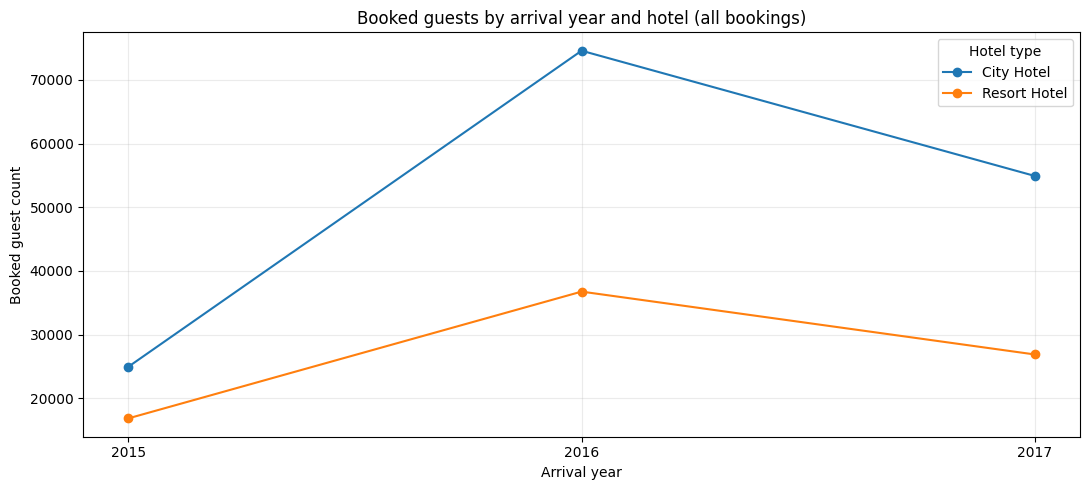

In [17]:
yearly_guests = guest_counts(
    bookings_copy, "arrival_date_year", include_canceled=INCLUDE_CANCELED_GUESTS
)
display(yearly_guests)
yearly_guest_figure = plot_hotel_trends(
    yearly_guests, "arrival_date_year", "guest_count",
    f"Booked guests by arrival year and hotel ({guest_scope})", "Booked guest count",
)
display(yearly_guest_figure)
plt.close(yearly_guest_figure)

## 16.1. Correlation Matrix
<a id="correlation-matrix"></a>

Calculate Pearson correlations between numeric columns in the analysis `bookings_copy`.
String categories and identifier codes are excluded. Missing values are excluded separately
for each pair; undefined correlations remain blank. Numeric calendar codes require careful
interpretation. Correlation describes association, not causation.
Run the following cell after creating `bookings_copy`. The plot is not exported.

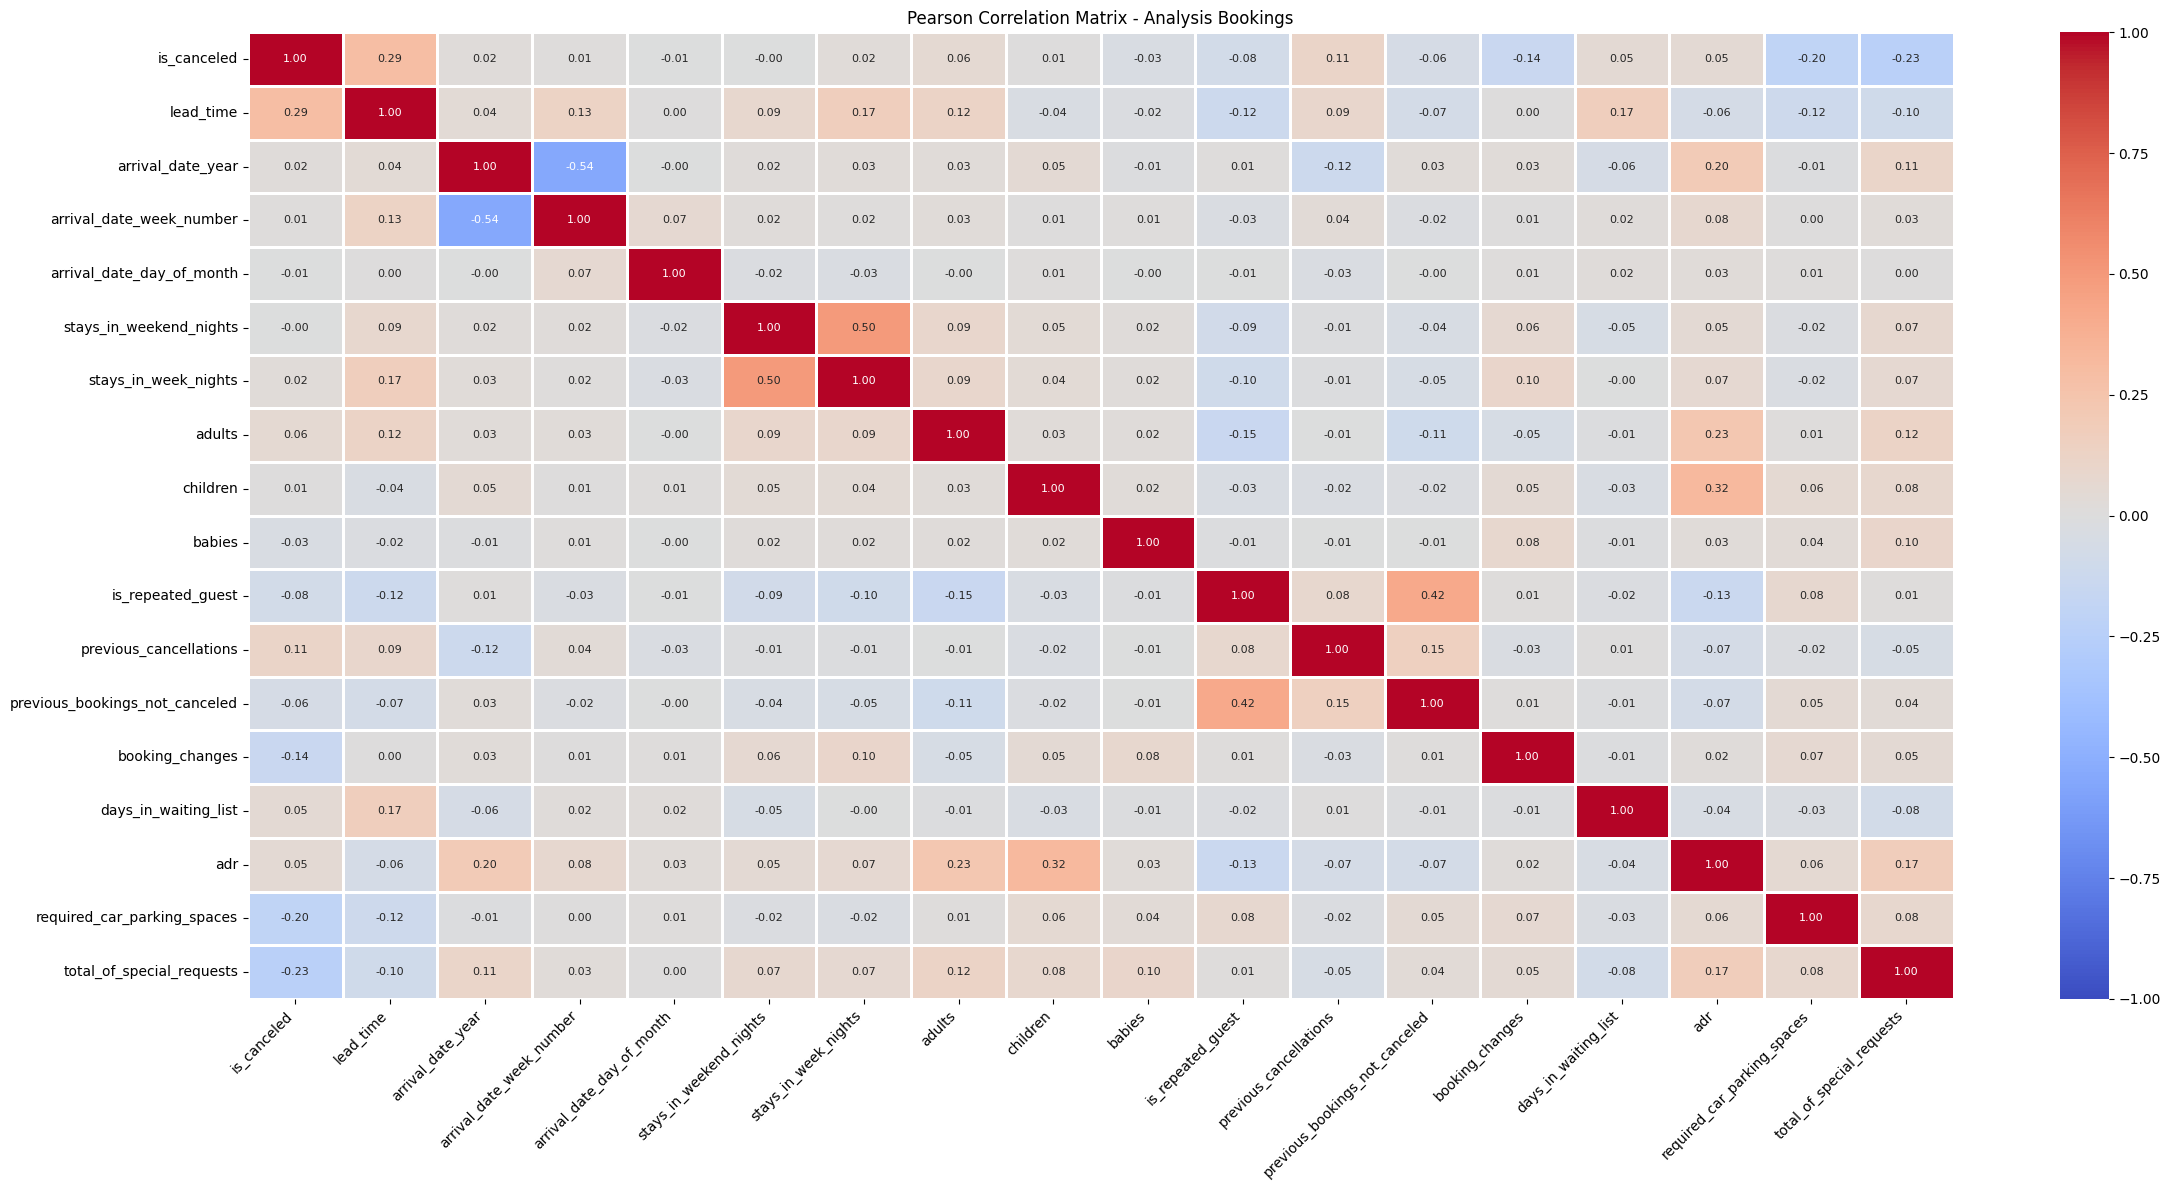

In [18]:
import seaborn as sns

corr = bookings_copy.select_dtypes(include="number").corr(method="pearson", min_periods=2)

correlation_figure, correlation_axis = plt.subplots(figsize=(24, 12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    linewidths=1,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8},
    ax=correlation_axis,
)
correlation_axis.set_title("Pearson Correlation Matrix - Analysis Bookings")
plt.setp(correlation_axis.get_xticklabels(), rotation=45, ha="right")
plt.setp(correlation_axis.get_yticklabels(), rotation=0)
correlation_figure.tight_layout()
display(correlation_figure)
plt.close(correlation_figure)

## 17. Chi-Square Test for Categorical Features

Test each listed categorical feature against the binary target `is_canceled` using the analysis
`bookings_copy`. Include explicitly selected numeric category codes (`arrival_date_year` and
`is_repeated_guest`), but exclude continuous measurements, the target itself, identifier codes
(`agent`, `company`), and the leakage columns (retained in the analysis copy).

- **H0:** The feature and cancellation status are independent.
- **H1:** They are associated.
- Use Pearson's chi-square test on category-by-target count tables, with no Yates correction.
- Exclude missing feature/target pairs separately for each feature; report excluded row counts.
- Use alpha = 0.05 and Bonferroni-adjusted p-values because multiple features are tested.
- Report expected counts. Flag tables if any expected count is below 1 or more than 20% are below 5.
  Flagged p-values require further review; categories are not automatically merged.
- A significant result indicates association, not its strength, direction, causality, or predictive
  usefulness. A nonsignificant result does not prove independence. Repeated guests can also violate
  the independent-observation assumption; removing exact duplicates alone does not resolve this.

Full count tables remain in memory in `contingency_tables`, for example
`display(contingency_tables["hotel"])`. No files are exported.

Extremely small p-values may display as zero because of floating-point underflow; this does not mean the probability is exactly zero.

In [19]:
import numpy as np
from scipy.stats import chi2_contingency

TARGET_COLUMN = "is_canceled"
CHI_SQUARE_ALPHA = 0.05
CATEGORICAL_FEATURES = (
    "hotel", "arrival_date_year", "arrival_date_month", "meal", "country",
    "market_segment", "distribution_channel", "is_repeated_guest",
    "reserved_room_type", "assigned_room_type", "deposit_type", "customer_type",
)


def chi_square_associations(frame, features, target, alpha=0.05):
    """Return per-feature independence checks and their observed count tables."""
    if target in features or len(features) != len(set(features)):
        raise ValueError("Features must be unique and must not include the target.")
    if not 0 < alpha < 1:
        raise ValueError("Alpha must be between zero and one.")
    missing_columns = sorted(set(features).union({target}) - set(frame.columns))
    if missing_columns:
        raise ValueError(f"Required columns not found: {missing_columns}")
    if set(frame[target].dropna().unique()) != {0, 1}:
        raise ValueError("The target must contain both binary classes: 0 and 1.")

    rows, tables = [], {}
    for feature in features:
        pairs = frame.loc[:, [feature, target]].dropna()
        observed = pd.crosstab(pairs[feature], pairs[target])
        tables[feature] = observed
        row = {
            "feature": feature, "rows_used": len(pairs),
            "rows_excluded": len(frame) - len(pairs),
            "categories": observed.shape[0],
        }
        if observed.shape[0] < 2 or observed.shape[1] < 2:
            row.update(chi2=np.nan, degrees_of_freedom=np.nan, p_value=np.nan,
                       min_expected=np.nan, expected_below_5_percent=np.nan,
                       assumption_warning=True, status="not_testable")
        else:
            statistic, p_value, degrees, expected = chi2_contingency(observed, correction=False)
            below_5_percent = 100 * (expected < 5).mean()
            row.update(
                chi2=statistic, degrees_of_freedom=degrees, p_value=p_value,
                min_expected=expected.min(), expected_below_5_percent=below_5_percent,
                assumption_warning=bool((expected < 1).any() or below_5_percent > 20),
                status="tested",
            )
        rows.append(row)
    summary = pd.DataFrame(rows)
    tested_count = int(summary["p_value"].notna().sum())
    summary["p_value_bonferroni"] = (summary["p_value"] * tested_count).clip(upper=1)
    summary["reject_h0_adjusted"] = summary["p_value_bonferroni"].lt(alpha).astype("boolean")
    summary.loc[summary["p_value"].isna(), "reject_h0_adjusted"] = pd.NA
    return summary.sort_values("p_value_bonferroni", na_position="last").reset_index(drop=True), tables

In [20]:
chi_square_summary, contingency_tables = chi_square_associations(
    bookings_copy, CATEGORICAL_FEATURES, TARGET_COLUMN, alpha=CHI_SQUARE_ALPHA
)

print(f"Target: {TARGET_COLUMN}; alpha: {CHI_SQUARE_ALPHA}; correction: Bonferroni")
display(chi_square_summary.style.format({
    "chi2": "{:.3f}",
    "p_value": "{:.3e}",
    "p_value_bonferroni": "{:.3e}",
    "min_expected": "{:.3f}",
    "expected_below_5_percent": "{:.2f}",
}, na_rep="Not available"))

flagged_features = chi_square_summary.loc[
    chi_square_summary["assumption_warning"], "feature"
].tolist()
print("Features requiring expected-frequency review:", flagged_features)
print("Significance alone does not measure association strength or feature importance.")

Target: is_canceled; alpha: 0.05; correction: Bonferroni


,feature,rows_used,rows_excluded,categories,chi2,degrees_of_freedom,p_value,min_expected,expected_below_5_percent,assumption_warning,status,p_value_bonferroni,reject_h0_adjusted
0,hotel,119390,0,2,2225.524,1,0.000e+00,14838.876,0.00,False,tested,0.000e+00,True
1,distribution_channel,119390,0,5,3745.794,4,0.000e+00,1.852,20.00,False,tested,0.000e+00,True
2,market_segment,119390,0,8,8497.224,7,0.000e+00,0.741,12.50,True,tested,0.000e+00,True
3,country,118902,488,177,15434.682,176,0.000e+00,0.371,46.05,True,tested,0.000e+00,True
4,deposit_type,119390,0,3,27677.329,2,0.000e+00,60.007,0.00,False,tested,0.000e+00,True
5,customer_type,119390,0,4,2222.504,3,0.000e+00,213.730,0.00,False,tested,0.000e+00,True
6,assigned_room_type,119390,0,12,4918.693,11,0.000e+00,0.370,12.50,True,tested,0.000e+00,True
7,is_repeated_guest,119390,0,2,858.405,1,1.082e-188,1411.286,0.00,False,tested,1.299e-187,True
8,reserved_room_type,119390,0,10,647.835,9,1.122e-133,2.222,15.00,False,tested,1.346e-132,True
9,arrival_date_month,119390,0,12,588.692,11,3.672e-119,2196.198,0.00,False,tested,4.406e-118,True


Features requiring expected-frequency review: ['market_segment', 'country', 'assigned_room_type']
Significance alone does not measure association strength or feature importance.


## 18. Integrity Checks

Confirm raw records remain unchanged and the analysis copy retains all rows and columns.
Leakage-column removal, deduplication and all-zero guest filtering run only in `src/preprocessing.py`.
Any future learned transformations must be fit only on training data.


In [21]:
assert pd.util.hash_pandas_object(raw_bookings, index=True).equals(raw_fingerprint)
assert bookings_copy.shape == raw_bookings.shape
assert bookings_copy.columns.equals(raw_bookings.columns)
assert bookings_copy.index.equals(raw_bookings.index)
print("Raw data unchanged; analysis copy retains all rows and columns.")
print(f"Final bookings_copy shape: {bookings_copy.shape}")


Raw data unchanged; analysis copy retains all rows and columns.
Final bookings_copy shape: (119390, 32)
